<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/14_Seq2Seq.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Modelo Seq2Seq</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Introducción</span>](#introduccion)
- [<span style="color: #005C99;">La arquitectura codificador-decodificador</span>](#la-arquitectura-codificador-decodificador)
- [<span style="color: #005C99;">Datos: pares español-inglés</span>](#datos-pares-espanol-ingles)
- [<span style="color: #005C99;">Vectorización</span>](#vectorizacion)
- [<span style="color: #005C99;">El modelo y el teacher forcing</span>](#el-modelo-y-el-teacher-forcing)
- [<span style="color: #005C99;">Entrenamiento</span>](#entrenamiento)
- [<span style="color: #005C99;">Decodificación voraz</span>](#decodificacion-voraz)
- [<span style="color: #005C99;">Búsqueda en haz</span>](#busqueda-en-haz)
- [<span style="color: #005C99;">Evaluación con BLEU</span>](#evaluacion-con-bleu)
- [<span style="color: #005C99;">El cuello de botella</span>](#el-cuello-de-botella)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib tensorflow nltk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # oculta mensajes informativos de TensorFlow

import re
import string
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)  # fija las semillas de Python, NumPy y TensorFlow

import random
import zipfile
import urllib.request
from io import BytesIO

from nltk.translate.bleu_score import corpus_bleu, sentence_bleu, SmoothingFunction

<a id="introduccion"></a>
<h2 style="color: #007ACC;">Introducción</h2>

Hasta ahora nuestras redes recurrentes producían **una etiqueta** por secuencia (sentimiento) o **una etiqueta por elemento** (el siguiente carácter). Muchas tareas de PLN, en cambio, transforman una secuencia en **otra secuencia de longitud distinta**:

| Tarea | Entrada | Salida |
|-------|---------|--------|
| Traducción automática | *Tengo hambre.* | *I'm hungry.* |
| Resumen | Una noticia | Su titular |
| Respuesta conversacional | Una pregunta | Una respuesta |
| Corrección / normalización | *q tal, nos vms mñn* | *¿Qué tal? Nos vemos mañana* |

El modelo **secuencia a secuencia** (*Seq2Seq*; Sutskever, Vinyals & Le, 2014; Cho et al., 2014) resolvió este problema con dos redes recurrentes y fue la base de los primeros traductores neuronales en producción, como Google Translate en 2016. En este cuaderno construiremos un traductor español → inglés.

<a id="la-arquitectura-codificador-decodificador"></a>
<h2 style="color: #007ACC;">La arquitectura codificador-decodificador</h2>

```text
            CODIFICADOR                                  DECODIFICADOR
"tengo" "mucha" "hambre"                      [start]   "i'm"   "very"  "hungry"
   ↓       ↓        ↓                            ↓        ↓        ↓        ↓
 [GRU] → [GRU] →  [GRU] ──── vector de contexto ──→ [GRU] → [GRU] → [GRU] → [GRU]
                                (estado final)       ↓        ↓        ↓        ↓
                                                   "i'm"   "very"  "hungry"  [end]
```

1. El **codificador** lee la oración de entrada y resume todo su contenido en su **estado final** $\mathbf{h}_T$: el **vector de contexto**.
2. El **decodificador** es un modelo de lenguaje **condicional**: su estado inicial es el vector de contexto, y genera la traducción palabra por palabra, cada una condicionada en las anteriores:

$$P(y_1, \dots, y_m \mid x_1, \dots, x_n) = \prod_{t=1}^{m} P(y_t \mid y_1, \dots, y_{t-1}, \mathbf{h}_T)$$

Los tokens especiales `[start]` y `[end]` marcan el inicio y el fin de la generación.

<a id="datos-pares-espanol-ingles"></a>
<h2 style="color: #007ACC;">Datos: pares español-inglés</h2>

Usaremos el corpus de pares de oraciones español-inglés del proyecto **Tatoeba** (distribuido por [manythings.org](https://www.manythings.org/anki/) y usado en los tutoriales de TensorFlow): unas 118 000 oraciones cortas de la vida cotidiana con su traducción.

In [3]:
URL = "http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip"
with zipfile.ZipFile(BytesIO(urllib.request.urlopen(URL).read())) as z:
    lineas = z.read("spa-eng/spa.txt").decode("utf-8").strip().split("\n")

pares = [tuple(linea.split("\t")[:2])[::-1] for linea in lineas]  # (español, inglés)
print(f"Pares: {len(pares):,}")
for es, en in random.Random(SEED).sample(pares, 5):
    print(f"  {es:<45} → {en}")

Pares: 118,964
  No hay ninguna duda sobre su habilidad.       → There is no doubt about his ability.
  Fueron maravillosos.                          → They were amazing.
  Durará.                                       → That'll last.
  Pasé las vacaciones decorando la casa.        → I spent the holidays decorating the house.
  Tengo el as de tréboles.                      → I have the ace of clubs.


Para que el entrenamiento sea rápido en CPU, nos quedamos con oraciones de **hasta 10 palabras** y tomamos una muestra. Separamos entrenamiento, validación y prueba.

In [4]:
pares_cortos = [(es, en) for es, en in pares if len(es.split()) <= 10 and len(en.split()) <= 10]
random.Random(SEED).shuffle(pares_cortos)
pares_cortos = pares_cortos[:60_000]

n_val = n_test = 2_000
train_pares = pares_cortos[:-(n_val + n_test)]
val_pares = pares_cortos[-(n_val + n_test):-n_test]
test_pares = pares_cortos[-n_test:]
print(f"Entrenamiento: {len(train_pares):,} | validación: {len(val_pares):,} | prueba: {len(test_pares):,}")

Entrenamiento: 56,000 | validación: 2,000 | prueba: 2,000


<a id="vectorizacion"></a>
<h2 style="color: #007ACC;">Vectorización</h2>

Vectorizamos cada idioma con su propia capa `TextVectorization`. Separamos los signos de puntuación como tokens independientes (en traducción importan: una pregunta debe traducirse como pregunta), y al inglés le añadimos los marcadores `[start]` y `[end]`. La secuencia de destino tiene una posición más, porque de ella sacaremos la entrada y la salida del decodificador desplazadas en uno.

In [5]:
def estandarizar(texto):
    texto = tf.strings.lower(texto)
    texto = tf.strings.regex_replace(texto, r"([¿?¡!.,])", r" \1 ")  # puntuación como tokens
    texto = tf.strings.regex_replace(texto, r"[^a-záéíóúüñ¿?¡!.,' \[\]]", "")
    return tf.strings.strip(tf.strings.regex_replace(texto, r"\s+", " "))


VOCAB, LONG = 12_000, 14
vec_es = layers.TextVectorization(VOCAB, output_sequence_length=LONG, standardize=estandarizar)
vec_en = layers.TextVectorization(VOCAB, output_sequence_length=LONG + 1, standardize=estandarizar)
vec_es.adapt([es for es, _ in train_pares])
vec_en.adapt(["[start] " + en + " [end]" for _, en in train_pares])
vocab_es = [str(w) for w in vec_es.get_vocabulary()]
vocab_en = [str(w) for w in vec_en.get_vocabulary()]
print(f"Vocabulario español: {len(vocab_es):,} | inglés: {len(vocab_en):,}")


def preparar(pares_):
    es = vec_es(np.array([p[0] for p in pares_])).numpy()
    en = vec_en(np.array(["[start] " + p[1] + " [end]" for p in pares_])).numpy()
    # Entradas: (oración en español, traducción desplazada) -> salida: traducción
    return (es, en[:, :-1]), en[:, 1:]


(X_tr_es, X_tr_en), Y_tr = preparar(train_pares)
(X_va_es, X_va_en), Y_va = preparar(val_pares)
print("español:            ", X_tr_es[0])
print("entrada decodificador:", [vocab_en[i] for i in X_tr_en[0] if i])
print("salida esperada:      ", [vocab_en[i] for i in Y_tr[0] if i])

Vocabulario español: 12,000 | inglés: 9,725


español:             [  9   4 104 121 368  36  94   8   0   0   0   0   0   0]
entrada decodificador: ['[start]', 'do', 'you', 'really', 'want', 'to', 'quit', 'your', 'job', '?', '[end]']
salida esperada:       ['do', 'you', 'really', 'want', 'to', 'quit', 'your', 'job', '?', '[end]']


<a id="el-modelo-y-el-teacher-forcing"></a>
<h2 style="color: #007ACC;">El modelo y el teacher forcing</h2>

Durante el **entrenamiento**, el decodificador recibe como entrada la traducción **correcta** desplazada una posición (`[start] i'm very hungry`) y debe predecir la siguiente palabra en cada posición (`i'm very hungry [end]`). Esto se llama ***teacher forcing***: aunque el modelo se equivoque en una palabra, en el paso siguiente recibe la palabra correcta. Así todas las posiciones se entrenan en paralelo y el aprendizaje es estable.

Durante la **inferencia** no conocemos la traducción: el decodificador recibe su propia predicción anterior. Esta diferencia entre entrenamiento e inferencia se conoce como **sesgo de exposición** (*exposure bias*): el modelo nunca practicó recuperarse de sus propios errores.

Usamos la API funcional de Keras. El estado final del codificador (`return_state=True`) se pasa como `initial_state` del decodificador. Las máscaras ignoran el relleno.

In [6]:
DIM_EMB, DIM_OCULTA = 256, 512

# Codificador
entrada_es = keras.Input(shape=(None,), dtype="int64", name="espanol")
emb_es = layers.Embedding(VOCAB, DIM_EMB, mask_zero=True, name="emb_es")(entrada_es)
_, estado_cod = layers.GRU(DIM_OCULTA, return_state=True, name="codificador")(emb_es)

# Decodificador
entrada_en = keras.Input(shape=(None,), dtype="int64", name="ingles_desplazado")
capa_emb_en = layers.Embedding(VOCAB, DIM_EMB, mask_zero=True, name="emb_en")
capa_gru_dec = layers.GRU(DIM_OCULTA, return_sequences=True, return_state=True, name="decodificador")
capa_salida = layers.Dense(VOCAB, name="logits")

salida_dec, _ = capa_gru_dec(capa_emb_en(entrada_en), initial_state=estado_cod)
logits = capa_salida(layers.Dropout(0.3)(salida_dec))

seq2seq = keras.Model([entrada_es, entrada_en], logits)


def perdida_enmascarada(y_true, y_pred):
    """Entropía cruzada que ignora las posiciones de relleno (índice 0)."""
    perdida = keras.losses.sparse_categorical_crossentropy(y_true, y_pred, from_logits=True)
    mascara = tf.cast(y_true != 0, perdida.dtype)
    return tf.reduce_sum(perdida * mascara) / tf.reduce_sum(mascara)


seq2seq.compile(optimizer="adam", loss=perdida_enmascarada)
seq2seq.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ espanol             │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ingles_desplazado   │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_es (Embedding)  │ (None, None, 256) │  3,072,000 │ espanol[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ espanol[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_en (Embedding)  │ (None, None, 256) │  3,072,000 │ ingles_desplazad… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ codificador (GRU)   │ [(None, 512),     │  1,182,720 │ emb_es[0][0],     │
│                     │ (None, 512)]      │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decodificador (GRU) │ [(None, None,     │  1,182,720 │ emb_en[0][0],     │
│                     │ 512), (None,      │            │ codificador[0][1] │
│                     │ 512)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, None, 512) │          0 │ decodificador[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logits (Dense)      │ (None, None,      │  6,156,000 │ dropout[0][0]     │
│                     │ 12000)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,665,440 (55.94 MB)

 Trainable params: 14,665,440 (55.94 MB)

 Non-trainable params: 0 (0.00 B)

<a id="entrenamiento"></a>
<h2 style="color: #007ACC;">Entrenamiento</h2>

Epoch 1/15


438/438 - 40s - 92ms/step - loss: 4.6254 - val_loss: 3.8126


Epoch 2/15


438/438 - 39s - 90ms/step - loss: 3.3408 - val_loss: 2.9299


Epoch 3/15


...

Epoch 10/15


438/438 - 39s - 90ms/step - loss: 0.6770 - val_loss: 1.7025


Epoch 11/15


438/438 - 39s - 90ms/step - loss: 0.5903 - val_loss: 1.7049


Entrenado en 435 s


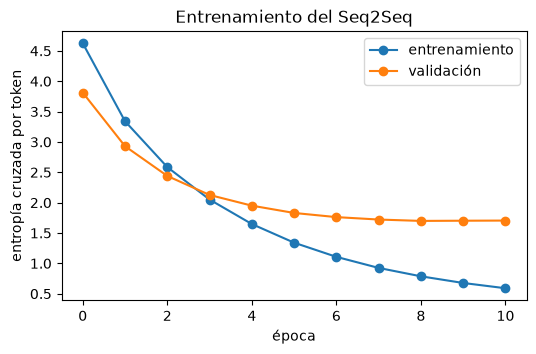

In [7]:
inicio = time.perf_counter()
historial = seq2seq.fit([X_tr_es, X_tr_en], Y_tr, validation_data=([X_va_es, X_va_en], Y_va),
                        epochs=15, batch_size=128, verbose=2,
                        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)])
print(f"Entrenado en {time.perf_counter() - inicio:.0f} s")

plt.figure(figsize=(6, 3.5))
plt.plot(historial.history["loss"], marker="o", label="entrenamiento")
plt.plot(historial.history["val_loss"], marker="o", label="validación")
plt.xlabel("época")
plt.ylabel("entropía cruzada por token")
plt.legend()
plt.title("Entrenamiento del Seq2Seq")
plt.show()

<a id="decodificacion-voraz"></a>
<h2 style="color: #007ACC;">Decodificación voraz</h2>

Para traducir separamos el modelo entrenado en dos piezas que comparten sus pesos:

- el **codificador**: oración → vector de contexto;
- un **paso del decodificador**: (palabra anterior, estado) → (distribución de la siguiente palabra, nuevo estado).

La **decodificación voraz** elige en cada paso la palabra más probable, hasta generar `[end]`.

In [8]:
codificador = keras.Model(entrada_es, estado_cod)

palabra_previa = keras.Input(shape=(1,), dtype="int64")
estado_previo = keras.Input(shape=(DIM_OCULTA,))
salida_paso, estado_nuevo = capa_gru_dec(capa_emb_en(palabra_previa), initial_state=estado_previo)
log_probs = layers.Activation("log_softmax")(capa_salida(salida_paso))
paso_decodificador = keras.Model([palabra_previa, estado_previo], [log_probs, estado_nuevo])

START, END = vocab_en.index("[start]"), vocab_en.index("[end]")


def traducir_voraz(oracion, max_len=LONG):
    estado = codificador(vec_es([oracion]), training=False)
    palabra, salida = START, []
    for _ in range(max_len):
        lp, estado = paso_decodificador([tf.constant([[palabra]], dtype="int64"), estado], training=False)
        palabra = int(np.argmax(lp[0, -1]))
        if palabra == END:
            break
        salida.append(vocab_en[palabra])
    return " ".join(salida)


for oracion in ["Tengo mucha hambre.", "¿Dónde está la estación de tren?", "Mi hermana estudia medicina en la universidad.",
                "No me gusta el café sin azúcar.", "Ayer llovió todo el día."]:
    print(f"{oracion:<48} → {traducir_voraz(oracion)}")

Tengo mucha hambre.                              → i am very hungry .
¿Dónde está la estación de tren?                 → where is the railway station ?


Mi hermana estudia medicina en la universidad.   → my sister is studying in the college of my college .
No me gusta el café sin azúcar.                  → i don't like coffee without sugar .


Ayer llovió todo el día.                         → it rained all day yesterday .


<a id="busqueda-en-haz"></a>
<h2 style="color: #007ACC;">Búsqueda en haz</h2>

La decodificación voraz puede equivocarse temprano y no tiene forma de corregirse: la palabra más probable en el paso 1 no siempre lleva a la traducción más probable completa. Buscar la secuencia óptima exacta es imposible ($|V|^m$ secuencias), y no podemos usar Viterbi porque el estado de la GRU no es un conjunto finito de estados.

La **búsqueda en haz** (*beam search*) es un compromiso: mantiene en cada paso las $k$ hipótesis parciales con mayor log-probabilidad acumulada, las expande todas y conserva otra vez las $k$ mejores. Con $k = 1$ es la decodificación voraz.

Como las log-probabilidades se suman (y son negativas), la búsqueda favorece las traducciones **cortas**. Por eso se normaliza el puntaje por la longitud: $\text{puntaje} = \frac{1}{m^{\alpha}} \sum_t \log P(y_t \mid \dots)$.

In [9]:
def traducir_haz(oracion, k=4, max_len=LONG, alpha=0.7):
    estado0 = codificador(vec_es([oracion]), training=False)
    haz = [([START], 0.0, estado0)]   # (secuencia, log-probabilidad, estado)
    terminadas = []
    for _ in range(max_len):
        # Expandimos todas las hipótesis del haz en una sola llamada al modelo
        palabras = tf.constant([[sec[-1]] for sec, _, _ in haz], dtype="int64")
        estados = tf.concat([e for _, _, e in haz], axis=0)
        lp, nuevos = paso_decodificador([palabras, estados], training=False)
        lp = lp[:, -1].numpy()
        candidatos = []
        for i, (sec, puntaje, _) in enumerate(haz):
            for palabra in np.argsort(-lp[i])[:k]:
                candidatos.append((sec + [int(palabra)], puntaje + lp[i, palabra], nuevos[i:i + 1]))
        candidatos.sort(key=lambda c: -c[1])
        haz = []
        for sec, puntaje, estado in candidatos:
            if sec[-1] == END:
                terminadas.append((sec, puntaje / (len(sec) - 1) ** alpha))
            else:
                haz.append((sec, puntaje, estado))
            if len(haz) == k:
                break
        if len(terminadas) >= k or not haz:
            break
    if not terminadas:  # ninguna hipótesis terminó: usamos las del haz
        terminadas = [(sec, p / (len(sec) - 1) ** alpha) for sec, p, _ in haz]
    mejor = max(terminadas, key=lambda t: t[1])[0]
    return " ".join(vocab_en[i] for i in mejor[1:] if i != END)


for oracion in ["Tengo mucha hambre.", "¿Dónde está la estación de tren?", "Mi hermana estudia medicina en la universidad.",
                "No me gusta el café sin azúcar.", "Ayer llovió todo el día."]:
    print(f"{oracion:<48} voraz: {traducir_voraz(oracion)}")
    print(f"{'':<48} haz:   {traducir_haz(oracion)}")

Tengo mucha hambre.                              voraz: i am very hungry .
                                                 haz:   i'm very hungry .


¿Dónde está la estación de tren?                 voraz: where is the railway station ?
                                                 haz:   where is the railway station ?


Mi hermana estudia medicina en la universidad.   voraz: my sister is studying in the college of my college .
                                                 haz:   my sister is studying in college in the college .


No me gusta el café sin azúcar.                  voraz: i don't like coffee without sugar .
                                                 haz:   i don't like coffee without sugar .


Ayer llovió todo el día.                         voraz: it rained all day yesterday .
                                                 haz:   it rained all day yesterday .


<a id="evaluacion-con-bleu"></a>
<h2 style="color: #007ACC;">Evaluación con BLEU</h2>

Evaluar traducciones a mano es costoso. La métrica automática clásica es **BLEU** (*Bilingual Evaluation Understudy*, Papineni et al., 2002), que mide cuántos N-gramas de la traducción del modelo aparecen en la traducción de referencia:

$$\text{BLEU} = \text{BP} \cdot \exp\left( \sum_{n=1}^{4} \frac{1}{4} \log p_n \right), \qquad \text{BP} = \min\left(1,\; e^{1 - r/c}\right)$$

- $p_n$ es la **precisión modificada** de N-gramas: la fracción de N-gramas de la traducción que aparecen en la referencia (sin contar más veces que en ella).
- BP es la **penalización por brevedad**: sin ella, una traducción de una sola palabra correcta tendría precisión perfecta ($c$ es la longitud de la traducción, $r$ la de la referencia).

BLEU va de 0 a 1 (o de 0 a 100). Se calcula sobre **todo el corpus de prueba**, no oración por oración. Sus limitaciones son conocidas: no reconoce sinónimos ni paráfrasis (*I'm hungry* frente a *I am hungry* comparten pocos N-gramas), y con una sola referencia por oración castiga traducciones correctas pero distintas.

In [10]:
def tokens_en(texto):
    return [str(t) for t in estandarizar(texto).numpy().decode().split()]


muestra = test_pares[:500]
referencias = [[tokens_en(en)] for _, en in muestra]

inicio = time.perf_counter()
hip_voraz = [traducir_voraz(es).split() for es, _ in muestra]
t_voraz = time.perf_counter() - inicio
inicio = time.perf_counter()
hip_haz = [traducir_haz(es).split() for es, _ in muestra]
t_haz = time.perf_counter() - inicio

pd.DataFrame({
    "BLEU": [corpus_bleu(referencias, hip_voraz), corpus_bleu(referencias, hip_haz)],
    "tiempo (s) para 500 oraciones": [t_voraz, t_haz],
}, index=["voraz", "haz (k=4)"]).round(3)

,BLEU,tiempo (s) para 500 oraciones
voraz,0.323,23.490
haz (k=4),0.362,29.518


In [11]:
suave = SmoothingFunction().method1
filas = []
for (es, en), hip in zip(muestra[:12], hip_haz[:12]):
    filas.append({"español": es, "referencia": en, "modelo": " ".join(hip),
                  "BLEU oración": round(sentence_bleu([tokens_en(en)], hip, smoothing_function=suave), 2)})
pd.set_option("display.max_colwidth", 60)
pd.DataFrame(filas)

,español,referencia,modelo,BLEU oración
0,Tuvimos un debate muy vigoroso.,We had a very vigorous debate.,we had a very shy audience .,0.43
1,No debería haberte besado.,I shouldn't have kissed you.,i shouldn't have called you .,0.25
2,"Me vuelvo a casa, ya me he hartado de Tom.",I'm going home. I've had enough of Tom.,"i'm going back home , tom has gone .",0.06
3,Estamos cómodos en nuestra nueva casa.,We are comfortable in our new house.,we're new under our new house .,0.36
4,Él es soltero todavía.,He's still single.,he is still unemployed .,0.06
5,Mi mamá se levanta temprano por la mañana.,My mother gets up early in the morning.,my mother gets up early every morning .,0.52
6,He estado preparándome.,I've been preparing.,i've been to canada .,0.13
7,Tom pensó que era injusto.,Tom thought it was unfair.,tom thought that he was unfair .,0.21
8,No pueden despedirles.,They can't fire you.,you can't escape .,0.08
9,Me alegro de que vengas.,I'm glad you're coming.,i'm glad it will come .,0.10


La búsqueda en haz mejora el BLEU en unos 4 puntos frente a la decodificación voraz, con un costo de tiempo moderado gracias a que expande todas las hipótesis en una sola llamada al modelo. En los ejemplos de arriba también se ven los errores típicos de un Seq2Seq pequeño: en *"Mi hermana estudia medicina en la universidad"* el modelo pierde *medicina* y repite *college*, porque el vector de contexto no conserva todos los detalles de la oración.

Revisa la tabla: algunas traducciones con BLEU bajo son perfectamente válidas pero usan otras palabras que la referencia (contracciones, sinónimos, otro orden). Por eso BLEU solo es útil para comparar **sistemas** sobre un corpus grande, no para juzgar oraciones individuales. Hoy se complementa con métricas basadas en modelos (como COMET o BERTScore) y con evaluación humana.

<a id="el-cuello-de-botella"></a>
<h2 style="color: #007ACC;">El cuello de botella</h2>

Todo lo que el decodificador sabe de la oración de entrada está comprimido en **un único vector** de 512 números. Para oraciones cortas basta, pero a medida que la oración se alarga, el vector de contexto tiene que guardar cada vez más información. ¿Cómo cambia la calidad con la longitud de la entrada?

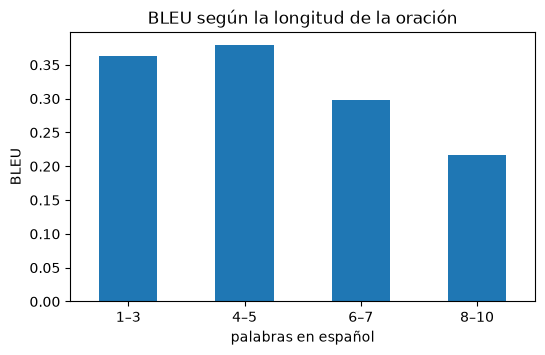

,oraciones,BLEU
palabras en español,,
1–3,250,0.363
4–5,250,0.380
6–7,250,0.297
8–10,250,0.216


In [12]:
# Usamos todo el conjunto de prueba, agrupado por número de palabras en español
longitudes = np.array([len(es.split()) for es, _ in test_pares])
grupos = {"1–3": (1, 3), "4–5": (4, 5), "6–7": (6, 7), "8–10": (8, 10)}
filas = []
for nombre, (a, b) in grupos.items():
    idx = np.where((longitudes >= a) & (longitudes <= b))[0][:250]
    refs = [[tokens_en(test_pares[i][1])] for i in idx]
    hips = [traducir_voraz(test_pares[i][0]).split() for i in idx]
    filas.append({"palabras en español": nombre, "oraciones": len(idx), "BLEU": corpus_bleu(refs, hips)})
por_longitud = pd.DataFrame(filas).set_index("palabras en español")
por_longitud["BLEU"].plot.bar(rot=0, figsize=(6, 3.5), title="BLEU según la longitud de la oración")
plt.ylabel("BLEU")
plt.show()
por_longitud.round(3)

La calidad cae con la longitud de la oración: el BLEU de las oraciones de 8–10 palabras es bastante menor que el de las de 4–5. Las oraciones muy cortas (1–3 palabras) tampoco son las más fáciles, porque suelen ser expresiones idiomáticas con muchas traducciones válidas. Y esto con oraciones de como máximo 10 palabras: en los experimentos originales (Cho et al., 2014) la calidad de los Seq2Seq sin atención **caía bruscamente** con oraciones de más de 20 palabras: un vector de tamaño fijo no alcanza para representar una oración larga.

La solución, propuesta por Bahdanau, Cho y Bengio (2015), es el **mecanismo de atención**: en lugar de usar solo el último estado del codificador, el decodificador puede **mirar todos los estados del codificador** en cada paso y decidir en cuáles concentrarse (por ejemplo, al generar *hungry* debería atender a *hambre*). La atención no solo resolvió el cuello de botella: es la idea central de los **Transformers**, el tema del módulo 4.

**Resumen del módulo 3:**

| Cuaderno | Idea |
|----------|------|
| 11 | Los embeddings son una capa entrenable: representaciones densas aprendidas para una tarea |
| 12 | Word2Vec y GloVe aprenden embeddings de significado general a partir de texto sin etiquetar |
| 13 | RNN, LSTM y GRU procesan el texto en orden y permiten modelos de lenguaje neuronales |
| 14 | Seq2Seq transforma secuencias en secuencias; su cuello de botella motiva la atención |

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Zhang, A., Lipton, Z. C., Li, M. & Smola, A. J. *Dive into Deep Learning*. [d2l.ai](https://d2l.ai/)
- Sutskever, I., Vinyals, O. & Le, Q. V. (2014). Sequence to Sequence Learning with Neural Networks. *NeurIPS*.
- Cho, K. et al. (2014). On the Properties of Neural Machine Translation: Encoder–Decoder Approaches. *SSST-8*.
- Bahdanau, D., Cho, K. & Bengio, Y. (2015). Neural Machine Translation by Jointly Learning to Align and Translate. *ICLR*.
- Papineni, K., Roukos, S., Ward, T. & Zhu, W.-J. (2002). BLEU: a Method for Automatic Evaluation of Machine Translation. *ACL*.
- Tiedemann, J. (2012). Parallel Data, Tools and Interfaces in OPUS. *LREC* (corpus Tatoeba).